# TP Integrador 2 — RAG local sobre protección de datos personales

Procesamiento de Lenguaje Natural — Tecnicatura Superior en Ciencias de Datos e Inteligencia Artificial (IFTS N.º 24).

---

## Objetivo

Este sistema permite que una persona responsable de un proyecto de datos, en un organismo público o en una empresa, consulte qué debe cumplir y qué se recomienda cuando su proyecto trata datos personales o usa IA (por ejemplo, cuándo necesita el consentimiento de los titulares, en qué casos conviene una evaluación de impacto o qué exigirle a un proveedor de nube), en la Ley 25.326 y en dos guías oficiales de la AAIP, para diseñar sus proyectos cumpliendo la normativa antes de ponerlos en marcha.

La Ley 25.326 es obligatoria; la Guía de la AAIP y los Lineamientos son recomendaciones.

## Producto esperado

Un índice Chroma local, una tabla de pruebas en `pruebas/auditoria.csv` y una interfaz Gradio que muestra la respuesta junto con los fragmentos enviados al modelo.

## Preguntas de prueba

Escritas antes de evaluar: 3 respondibles (R1–R3, una por documento), 2 sin respuesta (S1–S2) y 1 caso de limitación (L1), cuyo dato está en el PDF pero dentro de una imagen.

| # | Pregunta | Fuente esperada |
|---|---|---|
| R1 | ¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA? | Guía, p. 29 |
| R2 | ¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales? | Lineamientos, p. 27 |
| R3 | ¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones? | Ley 25.326, art. 5, p. 4 |
| S1 | ¿Cuánto tarda la AAIP en aprobar una evaluación de impacto? | No figura: debería abstenerse |
| S2 | ¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos? | No figura: debería abstenerse (trampa: la Ley dice que la consulta del registro es gratuita, art. 13, p. 7) |
| L1 | ¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico? | Guía, p. 30 (Figura 3): el dato está en una imagen que no se extrae; debería abstenerse |

## 1. Preparar el entorno y declarar los documentos

Los tres PDF están en `datos/` y se publican con el repositorio (ver `datos/LEEME.md`). Descargados el 13/11/2026.

**Guía de IA responsable (AAIP)**

| Campo | Dato |
|---|---|
| Fuente | Guía para entidades públicas y privadas en materia de Transparencia y Protección de Datos Personales para una Inteligencia Artificial responsable — AAIP, versión preliminar, junio de 2024. `guia_ia_responsable_aaip_2024.pdf` |
| Recorte | Páginas impresas 6 a 49 |
| Unidad de análisis | Una página del PDF, luego un fragmento con `source` y `page`. |
| Transformación previa | Ninguna: PDF original del organismo. |
| Límite | Versión preliminar; repite un encabezado propio en cada página (no se limpió). |
| Uso y redistribución | Creative Commons Atribución 4.0 (términos de argentina.gob.ar). |

**Lineamientos del Plan de Protección de Datos**

| Campo | Dato |
|---|---|
| Fuente | Lineamientos para la formulación de un Plan de Protección de Datos Personales — Consejo Federal para la Transparencia, editado por la AAIP, 2023. `lineamientos_plan_datos_cft_aaip_2023.pdf` |
| Recorte | Páginas impresas 9 a 30 |
| Unidad de análisis | Una página del PDF, luego un fragmento con `source` y `page`. |
| Transformación previa | Ninguna: PDF original del organismo. |
| Límite | Gráficos, columnas y saltos de línea pueden extraerse de forma incompleta. |
| Uso y redistribución | Creative Commons Atribución 4.0 (términos de argentina.gob.ar). |

**Ley 25.326**

| Campo | Dato |
|---|---|
| Fuente | Ley 25.326 de Protección de los Datos Personales, texto actualizado (incluye Ley 26.343, BO 9/1/2008) — Congreso de la Nación. `ley_25326_texto_actualizado.pdf` |
| Recorte | Páginas impresas 1 a 20 (la 21 solo tiene el pie) |
| Unidad de análisis | Una página del PDF, luego un fragmento con `source` y `page`. |
| Transformación previa | Página web de argentina.gob.ar guardada como PDF. El PDF nativo de la HCDN no estaba disponible (error 503). |
| Límite | Cada página conserva encabezado y pie del navegador (fecha, título, URL, «n/21»). No se limpió. |
| Uso y redistribución | Norma pública; Creative Commons Atribución 4.0 (términos de argentina.gob.ar). |

In [64]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter

load_dotenv(".env")
print("Librerías cargadas.")

Librerías cargadas.


## 2. Elegir un recorte que puedas controlar

De cada documento se indexa solo el cuerpo: Guía AAIP pp. 6–49 (de la Introducción a las Consideraciones finales), Lineamientos pp. 9–30 (de la Introducción a las Consideraciones finales) y Ley 25.326 pp. 1–20 (artículos 1 a 48). Se excluyen portadas, autoridades, índices, páginas en blanco, acrónimos, referencias y anexos, porque no aportan contenido para responder y agregarían ruido a la búsqueda. Las tres respuestas esperadas de las pruebas (Guía p. 29, Lineamientos p. 27, Ley p. 4) quedan dentro del recorte.

Los números de página son los **impresos** (empiezan en 1); LangChain los guarda en `metadata["page"]` desde 0, así que la conversión es `metadata["page"] + 1`.

In [65]:
MODELO_GENERADOR = os.getenv("OLLAMA_MODEL", "granite4:latest")
MODELO_EMBEDDINGS = os.getenv("OLLAMA_EMBEDDING_MODEL", "bge-m3")

# Cada documento: (ruta, página inicial, página final) con numeración impresa.
DOCUMENTOS = [
    (Path("datos/guia_ia_responsable_aaip_2024.pdf"), 6, 49),
    (Path("datos/lineamientos_plan_datos_cft_aaip_2023.pdf"), 9, 30),
    (Path("datos/ley_25326_texto_actualizado.pdf"), 1, 20),
]

for ruta, pagina_inicial, pagina_final in DOCUMENTOS:
    if not ruta.exists():
        raise FileNotFoundError(
            f"No encontré {ruta}. Copiá el PDF a la carpeta datos/ antes de seguir."
        )
    print(f"{ruta.name}: páginas {pagina_inicial} a {pagina_final}")

print("\nModelo generador:", MODELO_GENERADOR)
print("Modelo de embeddings:", MODELO_EMBEDDINGS)

guia_ia_responsable_aaip_2024.pdf: páginas 6 a 49
lineamientos_plan_datos_cft_aaip_2023.pdf: páginas 9 a 30
ley_25326_texto_actualizado.pdf: páginas 1 a 20

Modelo generador: granite4:latest
Modelo de embeddings: bge-m3


## 3. Cargar y revisar antes de indexar

Cargamos cada PDF completo, porque `PyPDFLoader` entrega una lista de páginas, y después nos quedamos solo con el rango de cada documento mediante `metadata["page"] + 1`. Todas las páginas del recorte quedan juntas en una lista, con el archivo en `source` y la página en `page`.

**Predicción.** 
Antes de ejecutar: 
1. ¿cuántas páginas esperás en total?: Espero 86 páginas, 44 de la Guía (6 a 49), 22 de los Lineamientos (9 a 30) y 20 de la Ley (1 a 20), contando la primera y la última de cada rango.
2. ¿Cuál creés que será más difícil de convertir a texto: una página de prosa o una con ilustración?: Creo que una página con ilustración será más difícil que una de prosa, porque PyPDFLoader solo lee la capa de texto del PDF y no convierte imágenes a texto.

In [66]:
paginas_del_recorte = []

for ruta, pagina_inicial, pagina_final in DOCUMENTOS:
    paginas_del_pdf = PyPDFLoader(str(ruta)).load()
    paginas_del_documento = []

    for pagina in paginas_del_pdf:
        pagina_impresa = pagina.metadata["page"] + 1

        if pagina_inicial <= pagina_impresa <= pagina_final:
            paginas_del_documento.append(pagina)

    print(
        f"{ruta.name}: {len(paginas_del_pdf)} páginas en el PDF, "
        f"{len(paginas_del_documento)} en el recorte"
    )
    assert len(paginas_del_documento) == pagina_final - pagina_inicial + 1
    paginas_del_recorte.extend(paginas_del_documento)

print("\nPáginas del recorte (3 documentos):", len(paginas_del_recorte))

guia_ia_responsable_aaip_2024.pdf: 62 páginas en el PDF, 44 en el recorte
lineamientos_plan_datos_cft_aaip_2023.pdf: 36 páginas en el PDF, 22 en el recorte
ley_25326_texto_actualizado.pdf: 21 páginas en el PDF, 20 en el recorte

Páginas del recorte (3 documentos): 86


In [67]:
def normalizar(texto):
    # El PDF corta líneas: se pasa a minúsculas y se unen los espacios.
    return " ".join(texto.lower().split())


# Caso, archivo, página impresa donde debería estar y evidencia esperada.
EVIDENCIAS = [
    # R1 original: "grandes volúmenes de datos" (también aparece en Guía p. 35 y p. 45).
    ("R1", "guia_ia_responsable_aaip_2024.pdf", 29, "son las que tratan grandes volúmenes de datos"),
    ("R2", "lineamientos_plan_datos_cft_aaip_2023.pdf", 27, "altos estándares de seguridad"),
    # R3 original: "libre, expreso e informado" (también aparece en Guía p. 20).
    ("R3", "ley_25326_texto_actualizado.pdf", 4, "no será necesario el consentimiento"),
]

for caso, archivo, pagina_esperada, evidencia in EVIDENCIAS:
    for pagina in paginas_del_recorte:
        es_la_pagina = (
            Path(pagina.metadata["source"]).name == archivo
            and pagina.metadata["page"] + 1 == pagina_esperada
        )
        if es_la_pagina:
            texto = pagina.page_content
            esta = normalizar(evidencia) in normalizar(texto)
            print(f"\n{'=' * 70}\n{caso} — {archivo}, página impresa {pagina_esperada}")
            print("Caracteres extraídos:", len(texto))
            print(f"Evidencia «{evidencia}» en el texto normalizado:", esta)
            print("-" * 70)
            print(texto[:800])


R1 — guia_ia_responsable_aaip_2024.pdf, página impresa 29
Caracteres extraídos: 2556
Evidencia «son las que tratan grandes volúmenes de datos» en el texto normalizado: True
----------------------------------------------------------------------
Evaluación de Impacto
La Evaluación de Impacto en la Protección de Datos en la etapa de diseño, es una herra-
mienta fundamental para identificar y mitigar riesgos asociados al tratamiento de datos 
personales en un sistema de Inteligencia Artificial desde el principio. 
Entre los riesgos que permite detectar está la reidentificación de personas, sesgos algorít-
micos, uso indebido de datos, entre otros, antes de que el sistema esté desarrollado. 
Por lo general aquellas organizaciones que deberían realizar una evaluación de impacto 
son las que tratan grandes volúmenes de datos, que realizan operaciones con datos sensi-
bles, o que realizan una indagación sistemática y exhaustiva de aspectos personales de las 
personas que se base en un tratami

In [68]:
# Página de control: la Guía p. 30 es la única página del recorte con una imagen
# (Figura 3, matriz de riesgos). No responde R1: sirve para comprobar la predicción
# «prosa vs ilustración» y es la página del caso L1.
for pagina in paginas_del_recorte:
    es_la_pagina = (
        Path(pagina.metadata["source"]).name == "guia_ia_responsable_aaip_2024.pdf"
        and pagina.metadata["page"] + 1 == 30
    )
    if es_la_pagina:
        texto = pagina.page_content
        print("Guía p. 30 — página con ilustración (Figura 3: matriz de riesgos)")
        print("Caracteres extraídos:", len(texto))
        print("-" * 70)
        print(texto)

Guía p. 30 — página con ilustración (Figura 3: matriz de riesgos)
Caracteres extraídos: 2172
----------------------------------------------------------------------
Figura 3: Matriz de riesgos 
Guías y recomendaciones para la evaluación de impacto en un sistema de IA
Para mayor detalle, se recomienda tomar como referencia la evaluación de impacto ética 
publicada por la UNESCO, la que principalmente tiene como objetivo evaluar si los algoritmos 
se encuentran alineados con los valores, principios y orientaciones establecidos por su Reco-
mendación. Esta evaluación debería garantizar la transparencia siendo abierta al público la 
información sobre estos sistemas y cómo se desarrollaron.
Oportunamente, la AAIP de Argentina y la Unidad Reguladora y de Control de Datos Personales de 
Uruguay, publicaron una Guía “Evaluación de Impacto en la Protección de Datos”. Este instrumen-
to no fue desarrollado específicamente para la evaluación de impacto de sistemas que utilicen la 
Inteligencia Art

**Observación de la extracción.** Se comparó cada página con el PDF abierto en la misma página impresa. El contenido de las tres páginas de prosa coincide con el PDF; el ruido que aparece es:

- **Guía (R1, p. 29):** el encabezado («Guía para entidades públicas y privadas…») y el pie propio del PDF («29 | Recomendaciones de Transparencia…») se extraen, pero desplazados al final del texto de la página. El pie con logos de la institución es una imagen y no se extrae. Hay palabras cortadas con guion («herra- mienta», «sensi- bles»).
- **Lineamientos (R2, p. 27):** texto limpio; el número de página aparece al inicio y hay algún corte de palabra («su - puesto»).
- **Ley (R3, p. 4):** conserva el encabezado y el pie del navegador (fecha, título, URL, «4/21») al final de la página.

Este ruido no se limpió: se declara como límite del corpus.


**Observación de predicciones.** 

1. Se cargaron 86 páginas, como esperaba. El assert confirma el recorte exacto de cada documento.

2. Las páginas de prosa (Guía p. 29, Lineamientos p. 27, Ley p. 4) se extraen completas y coinciden con el PDF, con defectos menores: palabras cortadas con guion en la Guía («sensi- bles») y encabezados repetidos en la Guía y la Ley. La página con ilustración (Guía p. 30, Figura 3) confirma la predicción: la matriz de riesgos es una imagen y su contenido (ejes, valores y colores) no se extrae; solo queda la leyenda como texto suelto. Por eso L1 no debería poder responderse.

## 4. Medir antes de decidir cómo cortar

Antes de elegir un tamaño de fragmento conviene saber cuánto texto tiene cada página: una página con muy pocos caracteres puede ser una portada, una página casi vacía o una imagen que no se extrajo. El gráfico muestra los caracteres extraídos por página de cada documento.

guia_ia_responsable_aaip_2024.pdf: mínimo 946 (p. 10), máximo 3433 (p. 12), mediana 2290
lineamientos_plan_datos_cft_aaip_2023.pdf: mínimo 1159 (p. 28), máximo 3005 (p. 15), mediana 2319
ley_25326_texto_actualizado.pdf: mínimo 1092 (p. 1), máximo 2638 (p. 12), mediana 2228


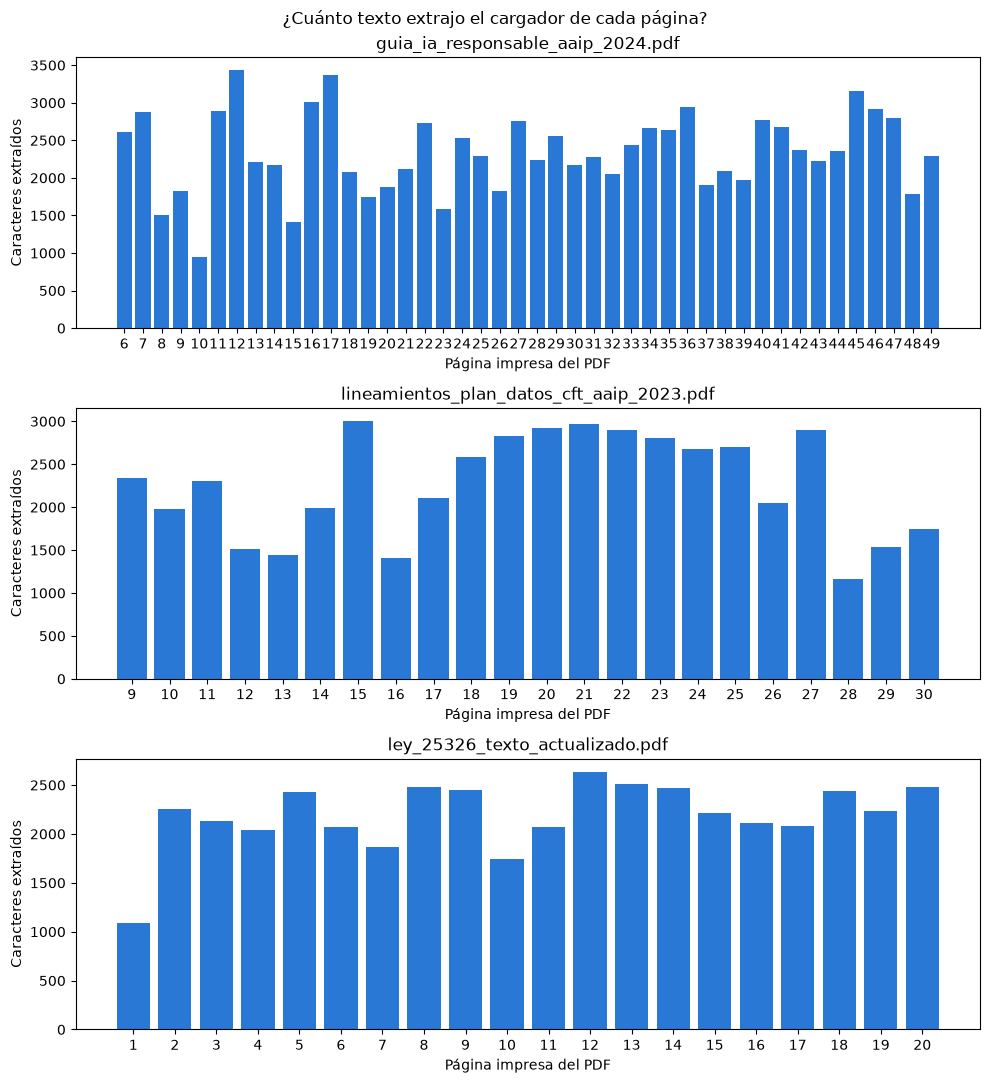

In [69]:
import statistics

fig, ejes = plt.subplots(len(DOCUMENTOS), 1, figsize=(10, 11))

for eje, (ruta, pagina_inicial, pagina_final) in zip(ejes, DOCUMENTOS):
    numeros_de_pagina = []
    caracteres_por_pagina = []

    for pagina in paginas_del_recorte:
        if Path(pagina.metadata["source"]).name == ruta.name:
            numeros_de_pagina.append(pagina.metadata["page"] + 1)
            caracteres_por_pagina.append(len(pagina.page_content))

    eje.bar(numeros_de_pagina, caracteres_por_pagina, color="#2a78d6")
    eje.set_title(ruta.name)
    eje.set_xlabel("Página impresa del PDF")
    eje.set_ylabel("Caracteres extraídos")
    eje.set_xticks(numeros_de_pagina)

    pagina_minima = numeros_de_pagina[caracteres_por_pagina.index(min(caracteres_por_pagina))]
    pagina_maxima = numeros_de_pagina[caracteres_por_pagina.index(max(caracteres_por_pagina))]
    print(
        f"{ruta.name}: mínimo {min(caracteres_por_pagina)} (p. {pagina_minima}), "
        f"máximo {max(caracteres_por_pagina)} (p. {pagina_maxima}), "
        f"mediana {statistics.median(caracteres_por_pagina):.0f}"
    )

fig.suptitle("¿Cuánto texto extrajo el cargador de cada página?")
plt.tight_layout()
plt.show()

 **Observación** 

Ninguna página quedó vacía: el mínimo es 946 caracteres (Guía p. 10), así que los tres PDF tienen texto extraíble y no hace falta OCR. La mediana es parecida en los tres documentos (entre 2.228 y 2.319 caracteres por página): con un corte de 500 caracteres una página típica se divide en 4 o 5 fragmentos y con 1.100 en unos 2. La Guía p. 30 tiene un largo normal (~2.170) aunque perdió la Figura 3: contar caracteres detecta páginas vacías, pero no contenido perdido dentro de una página con texto. Las páginas más cortas (Guía p. 10, Ley p. 1, Lineamientos p. 28) quedan para revisar en el PDF. 

Las páginas más cortas tienen explicación: la Guía p. 10 es el inicio del capítulo «Alcance» con un solo párrafo, y la Ley p. 1 es la portada de la norma. La Lineamientos p. 28 tiene dos gráficos de una encuesta: sus etiquetas y porcentajes se extraen como texto suelto, sin la relación entre valor y categoría, una pérdida similar a la de la Figura 3 de la Guía.

## 5. Comparar dos formas de fragmentar

No hay un tamaño universal. Mantenemos el mismo corpus (las 86 páginas del recorte) y comparamos dos decisiones con la misma pregunta.

| Versión | `chunk_size` | `chunk_overlap` | Pregunta para inspeccionar |
|---|---:|---:|---|
| Breve | 500 | 80 | R3: ¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones? |
| Amplia | 1.100 | 180 | R3 (la misma) |

Elegimos R3 porque el art. 5 de la Ley (p. 4) tiene la regla y una lista larga de excepciones: un corte corto puede separarlas. `chunk_size` y `chunk_overlap` se miden en caracteres; el solapamiento conserva el final de un fragmento al comienzo del siguiente. Probá cambiar **un valor por vez**.



In [70]:
from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings

TAMANO_BREVE = 500
SOLAPAMIENTO_BREVE = 80
TAMANO_AMPLIO = 1100
SOLAPAMIENTO_AMPLIO = 180

divisor_breve = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_BREVE,
    chunk_overlap=SOLAPAMIENTO_BREVE,
)
divisor_amplio = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_AMPLIO,
    chunk_overlap=SOLAPAMIENTO_AMPLIO,
)

fragmentos_breves = divisor_breve.split_documents(paginas_del_recorte)
fragmentos_amplios = divisor_amplio.split_documents(paginas_del_recorte)

print("Fragmentos breves:", len(fragmentos_breves))
print("Fragmentos amplios:", len(fragmentos_amplios))
print("Primer fragmento breve:\n", fragmentos_breves[0].page_content[:500])

Fragmentos breves: 483
Fragmentos amplios: 239
Primer fragmento breve:
 El desarrollo y el uso de los sistemas que integran tecnologías de Inteligencia Artificial ha crecido 
exponencialmente en los últimos años. El mundo se encuentra ante una cuarta revolución indus-
trial potenciada por estos nuevos sistemas que generan cambios aceleradamente y de una forma 
mucho más abrupta que las revoluciones industriales anteriores. La IA tiene el potencial de 
mejorar el bienestar de las personas, aumentar la innovación y la productividad y ayudar a


In [71]:
pregunta_de_comparacion = (
    "¿Necesito el consentimiento de las personas para usar sus datos personales "
    "en mi proyecto? ¿Hay excepciones?"
)
embeddings = OllamaEmbeddings(model=MODELO_EMBEDDINGS)

vector_pregunta = embeddings.embed_query(pregunta_de_comparacion)
vector_breve = embeddings.embed_query(fragmentos_breves[10].page_content)
vector_amplio = embeddings.embed_query(fragmentos_amplios[5].page_content)

print("Dimensiones del vector de la pregunta:", len(vector_pregunta))
print("Dimensiones del vector breve:", len(vector_breve))
print("Dimensiones del vector amplio:", len(vector_amplio))
print("Los tres vectores deben tener la misma dimensión porque usan", MODELO_EMBEDDINGS)

Dimensiones del vector de la pregunta: 1024
Dimensiones del vector breve: 1024
Dimensiones del vector amplio: 1024
Los tres vectores deben tener la misma dimensión porque usan bge-m3


In [73]:
# Dos índices temporales en memoria (sin persist_directory): solo para comparar.
# La distancia menor indica mayor cercanía; no es una probabilidad.
K = 3
evidencia_r3 = "no será necesario el consentimiento"

# Si la celda se vuelve a ejecutar, se borran las colecciones temporales
# anteriores para no sumar fragmentos repetidos.
for nombre_coleccion in ["comparacion_breve", "comparacion_amplio"]:
    Chroma(collection_name=nombre_coleccion, embedding_function=embeddings).delete_collection()

# Indexación por lotes, igual que en la sección 6: enviar todos los fragmentos
# en una sola llamada hacía que Ollama cortara el proceso de bge-m3.
TAMANO_LOTE = 50

indice_breve = Chroma(collection_name="comparacion_breve", embedding_function=embeddings)
for inicio in range(0, len(fragmentos_breves), TAMANO_LOTE):
    indice_breve.add_documents(documents=fragmentos_breves[inicio:inicio + TAMANO_LOTE])

indice_amplio = Chroma(collection_name="comparacion_amplio", embedding_function=embeddings)
for inicio in range(0, len(fragmentos_amplios), TAMANO_LOTE):
    indice_amplio.add_documents(documents=fragmentos_amplios[inicio:inicio + TAMANO_LOTE])

print("Índice breve:", indice_breve._collection.count(), "fragmentos")
print("Índice amplio:", indice_amplio._collection.count(), "fragmentos")

for nombre, indice in [("Breve", indice_breve), ("Amplio", indice_amplio)]:
    hallazgos = indice.similarity_search_with_score(query=pregunta_de_comparacion, k=K)
    textos_normalizados = [normalizar(documento.page_content) for documento, _ in hallazgos]
    evidencia_en_top_k = any(normalizar(evidencia_r3) in texto for texto in textos_normalizados)

    print(f"\n{'=' * 70}\n{nombre} — evidencia «{evidencia_r3}» en el top-{K}: {evidencia_en_top_k}")
    for numero, (documento, distancia) in enumerate(hallazgos, start=1):
        archivo = Path(documento.metadata["source"]).name
        pagina = documento.metadata["page"] + 1
        print(f"[{numero}] {archivo} p. {pagina} — distancia {distancia:.3f}")

    primer_documento = hallazgos[0][0]
    print("\nPrimer hallazgo:\n", primer_documento.page_content)

Índice breve: 483 fragmentos
Índice amplio: 239 fragmentos

Breve — evidencia «no será necesario el consentimiento» en el top-3: False
[1] guia_ia_responsable_aaip_2024.pdf p. 20 — distancia 0.686
[2] ley_25326_texto_actualizado.pdf p. 12 — distancia 0.760
[3] ley_25326_texto_actualizado.pdf p. 6 — distancia 0.771

Primer hallazgo:
 establece la ley y las reglamentaciones vigentes. 
Consentimiento: el tratamiento de datos personales requiere el consentimiento libre, expreso 
e informado del titular de los datos.
Finalidad: Los datos personales sólo pueden ser tratados para fines específicos y legítimos, 
previamente informados al titular.
Guía para entidades públicas  y privadas en materia de Transparencia y Protección de 
Datos Personales para una Inteligencia Artificial responsable

Amplio — evidencia «no será necesario el consentimiento» en el top-3: True
[1] guia_ia_responsable_aaip_2024.pdf p. 33 — distancia 0.771
[2] guia_ia_responsable_aaip_2024.pdf p. 28 — distancia 0.822
[3] l

Usamos K=3 (y no K=1 como en la sección 5 del cuaderno 07 de laboratorio) para comparar los cortes con el mismo número de fragmentos que va a recibir el modelo (K=3, como en las secciones 7 y 9 del 07). Con tres documentos que tratan el consentimiento, la fuente esperada puede no quedar primera: en el corte amplio, la Ley p. 4 aparece en tercer lugar. Con la evidencia «no será necesario el consentimiento» (que solo aparece en el art. 5), el chequeo da False para el corte breve y True para el amplio.

### Decisión de fragmentación

- **Unidad:** chunk_size y chunk_overlap se miden en caracteres (incluye espacios y saltos de línea), no en palabras ni en tokens. Con una página típica de ~2.300 caracteres, 500 equivale a un cuarto de página y 1.100 a media página.

- **Qué mostró la comparación con R3:** El corte breve (500/80) generó 483 fragmentos y el amplio (1.100/180), 239. Con el breve, el top-3 trae la regla del consentimiento desde una lista de principios de la Guía (p. 20), pero no las excepciones ni la Ley p. 4 (art. 5). Con el amplio, el primer fragmento (Guía p. 33) contiene la regla y sus excepciones juntas, y la Ley p. 4 aparece en tercer lugar.

- **Decisión:** Para la pregunta sobre consentimiento elegiría el corte amplio porque mantiene juntas la regla y sus excepciones. El riesgo que observo es que un fragmento amplio mezcla temas (el de la Guía p. 33 termina en «Medidas de seguridad») y le pasa al modelo texto que no responde la pregunta.

- **Hipótesis y cómo se va a comprobar:** Esta comparación mira solo qué fragmentos trae el buscador, sin modelo que responda, así que es una hipótesis: con el corte breve, la respuesta a R3 podría salir incompleta (la regla sin las excepciones). Se comprueba en la auditoría: la corrida 1 usa el corte base de clase (500/80) como punto de partida y la corrida 2 cambia solo el corte a 1.100/180. Si R3 mejora, la hipótesis se confirma; si no, se documenta igual.

## 6. Índice persistente y modelo de embeddings

Para indexar los fragmentos y para convertir cada pregunta en un vector se usa **el mismo modelo**: `MODELO_EMBEDDINGS`, leído de `.env` (`bge-m3`). Tiene que ser el mismo en las dos puntas porque cada modelo construye su propio espacio de vectores: si la pregunta se representa con un modelo y los fragmentos con otro, las distancias no significan nada (y si además cambia la dimensión, la búsqueda directamente falla).

El nombre de la colección, `integrador_500_80_bge_m3`, incluye el corte (500/80) y el modelo (bge-m3). Si cambia cualquiera de los dos, es **otro índice**: se crea una colección nueva y no se mezclan vectores. Esta celda reconstruye su propia colección cada vez que se ejecuta, así no queda ningún fragmento de una configuración anterior. Se indexa la versión breve (500/80), que es la base de la corrida 1.

In [74]:
CARPETA_INDICE = "chroma_db_integrador"
NOMBRE_COLECCION = "integrador_500_80_bge_m3"

indice_rag = Chroma(
    collection_name=NOMBRE_COLECCION,
    embedding_function=embeddings,
    persist_directory=CARPETA_INDICE,
)

# Si la colección ya tiene datos, se borra y se recrea para no duplicar fragmentos.
if indice_rag.get(limit=1)["ids"]:
    indice_rag.delete_collection()
    indice_rag = Chroma(
        collection_name=NOMBRE_COLECCION,
        embedding_function=embeddings,
        persist_directory=CARPETA_INDICE,
    )

identificadores = []
for numero in range(len(fragmentos_breves)):
    identificadores.append(f"fragmento_{numero}")

# Versión original: enviaba los 483 fragmentos en una sola llamada y Ollama
# cortaba el proceso de bge-m3 a mitad de camino.
#indice_rag.add_documents(documents=fragmentos_breves, ids=identificadores)


# Se indexa por lotes para no sobrecargar a Ollama con 483 fragmentos de una vez.
TAMANO_LOTE = 50
for inicio in range(0, len(fragmentos_breves), TAMANO_LOTE):
    fin = inicio + TAMANO_LOTE
    indice_rag.add_documents(
        documents=fragmentos_breves[inicio:fin],
        ids=identificadores[inicio:fin],
    )
    print("Indexados hasta el fragmento", min(fin, len(fragmentos_breves)))


print("Colección:", NOMBRE_COLECCION)
print("Fragmentos indexados:", len(indice_rag.get()["ids"]))

Indexados hasta el fragmento 50
Indexados hasta el fragmento 100
Indexados hasta el fragmento 150
Indexados hasta el fragmento 200
Indexados hasta el fragmento 250
Indexados hasta el fragmento 300
Indexados hasta el fragmento 350
Indexados hasta el fragmento 400
Indexados hasta el fragmento 450
Indexados hasta el fragmento 483
Colección: integrador_500_80_bge_m3
Fragmentos indexados: 483


In [75]:
# Comprobación (a): la cantidad indexada coincide con la cantidad de fragmentos.
cantidad_indexada = len(indice_rag.get()["ids"])
print("Fragmentos indexados:", cantidad_indexada, "| fragmentos breves:", len(fragmentos_breves))
assert cantidad_indexada == len(fragmentos_breves)

# Comprobación (b): el vector guardado en el índice y el de una pregunta
# tienen la misma dimensión, porque salen del mismo modelo.
vector_guardado = indice_rag.get(ids=["fragmento_0"], include=["embeddings"])["embeddings"][0]
vector_de_pregunta = embeddings.embed_query(pregunta_de_comparacion)
print(
    "Dimensión del vector guardado:", len(vector_guardado),
    "| dimensión del vector de la pregunta:", len(vector_de_pregunta),
)
assert len(vector_guardado) == len(vector_de_pregunta)

Fragmentos indexados: 483 | fragmentos breves: 483
Dimensión del vector guardado: 1024 | dimensión del vector de la pregunta: 1024


**Observación.** 

Observación. Se indexaron los 483 fragmentos breves (500/80) en la colección integrador_500_80_bge_m3: la cantidad indexada coincide con la cantidad de fragmentos, y el vector guardado y el de la pregunta tienen la misma dimensión (1024), lo que confirma que índice y consulta usan el mismo modelo (bge-m3). La primera versión enviaba los 483 fragmentos en una sola llamada y Ollama se cortaba a mitad de camino; se pasó a lotes de 50, que producen el mismo índice y muestran el avance.

## 7. Recuperar evidencia antes de generar (k)

`K` es la cantidad de fragmentos que entran al contexto del modelo; acá usamos `K = 3`. Antes de generar nada, miramos qué llega para cada una de las 6 preguntas de prueba: de qué archivo y página viene cada fragmento, qué dice y si contiene la evidencia esperada. La distancia menor indica mayor cercanía; no es una probabilidad. En esta sección no se genera ninguna respuesta.

In [76]:
import pandas as pd

from utils_visualizacion import dibujar_barras

K = 3

# Caso, pregunta y fuente esperada (tabla «Preguntas de prueba»).
casos = [
    ("R1", "¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?", "Guía, p. 29"),
    ("R2", "¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?", "Lineamientos, p. 27"),
    ("R3", "¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?", "Ley 25.326, art. 5, p. 4"),
    ("S1", "¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?", "No figura: debería abstenerse"),
    ("S2", "¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?", "No figura: debería abstenerse (la Ley dice que la consulta del registro es gratuita, art. 13, p. 7)"),
    ("L1", "¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?", "Guía, p. 30 (Figura 3): el dato está en una imagen que no se extrae; debería abstenerse"),
]

# Evidencia esperada: solo R1, R2 y R3 la tienen; S1, S2 y L1 quedan en None.
evidencias = {}
for caso, archivo, pagina_esperada, evidencia in EVIDENCIAS:
    evidencias[caso] = evidencia


R1 — ¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?
Fuente esperada: Guía, p. 29

[1] guia_ia_responsable_aaip_2024.pdf, p. 36 — distancia 0.523
comprensión de la IA.
Evaluar el impacto del proyecto en la protección de datos personales desde el inicio, 
incluyendo riesgos e impactos adversos.
Considerar la privacidad por diseño y por defecto para que sean objeto de tratamiento 
solo aquellos datos personales necesarios.
Garantizar que la fue

[2] guia_ia_responsable_aaip_2024.pdf, p. 29 — distancia 0.539
Evaluación de Impacto
La Evaluación de Impacto en la Protección de Datos en la etapa de diseño, es una herra-
mienta fundamental para identificar y mitigar riesgos asociados al tratamiento de datos 
personales en un sistema de Inteligencia Artificial desde el principio. 
Entre los riesgos que permit

[3] guia_ia_responsable_aaip_2024.pdf, p. 30 — distancia 0.664
información sobre estos sistemas y cómo

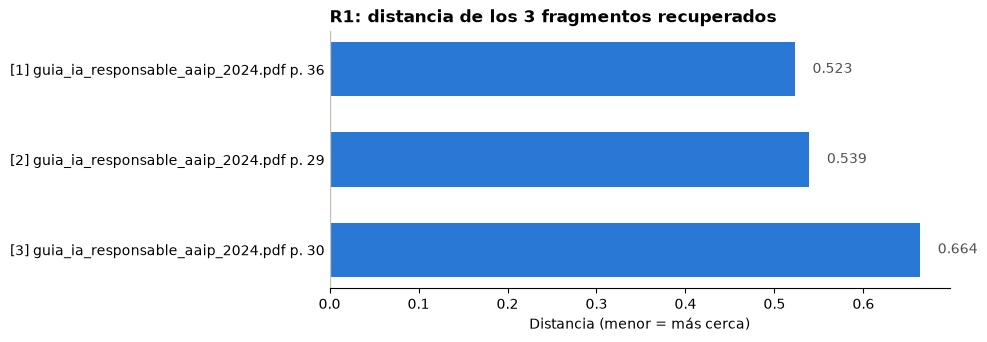


R2 — ¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?
Fuente esperada: Lineamientos, p. 27

[1] lineamientos_plan_datos_cft_aaip_2023.pdf, p. 27 — distancia 0.527
cada vez mayor para la privacidad de las personas. Al seleccionar un proveedor 
de servicios en la nube, es fundamental investigar y elegir uno que ofrezca altos 
estándares de seguridad y cumpla con las regulaciones de privacidad.
En el país no hay muchos prestadores del servicio, por lo que la may

[2] lineamientos_plan_datos_cft_aaip_2023.pdf, p. 27 — distancia 0.650
es necesario un acuerdo con el encargado de tratamiento, que debe detallar el 
objeto y el alcance del acuerdo, el plazo, la ubicación, la naturaleza y la finalidad, 
qué categoría de datos personales serán tratados. Algunos encargados sostie-
nen que al alojar datos en la nube no tratan datos perso

[3] lineamientos_plan_datos_cft_aaip_2023.pdf, p. 27 — distancia 0.685
27
7.  
Alojamiento en la nube
El cloud hosting o

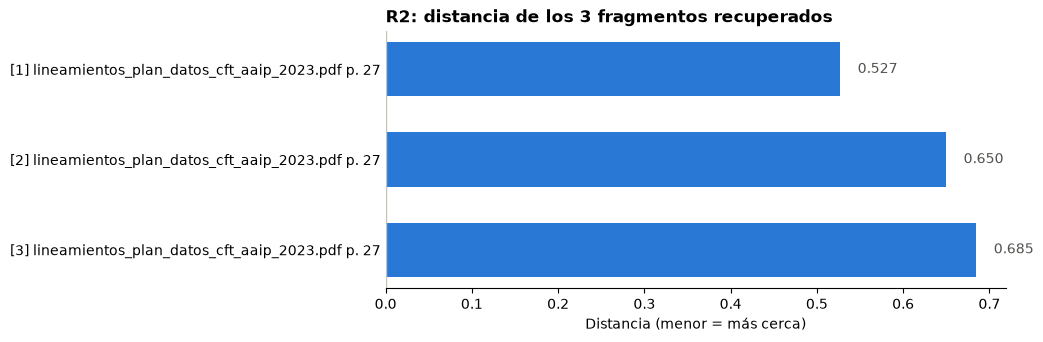


R3 — ¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?
Fuente esperada: Ley 25.326, art. 5, p. 4

[1] guia_ia_responsable_aaip_2024.pdf, p. 20 — distancia 0.686
establece la ley y las reglamentaciones vigentes. 
Consentimiento: el tratamiento de datos personales requiere el consentimiento libre, expreso 
e informado del titular de los datos.
Finalidad: Los datos personales sólo pueden ser tratados para fines específicos y legítimos, 
previamente informados 

[2] ley_25326_texto_actualizado.pdf, p. 12 — distancia 0.760
inteligencia; y aquellos sobre antecedentes personales que proporcionen dichos bancos de
datos a las autoridades administrativas o judiciales que los requieran en virtud de
disposiciones legales.
2. El tratamiento de datos personales con fines de defensa nacional o seguridad pública
por parte de las

[3] ley_25326_texto_actualizado.pdf, p. 6 — distancia 0.771
pública.
ARTICULO 11. — (Cesión).
1. Los datos persona

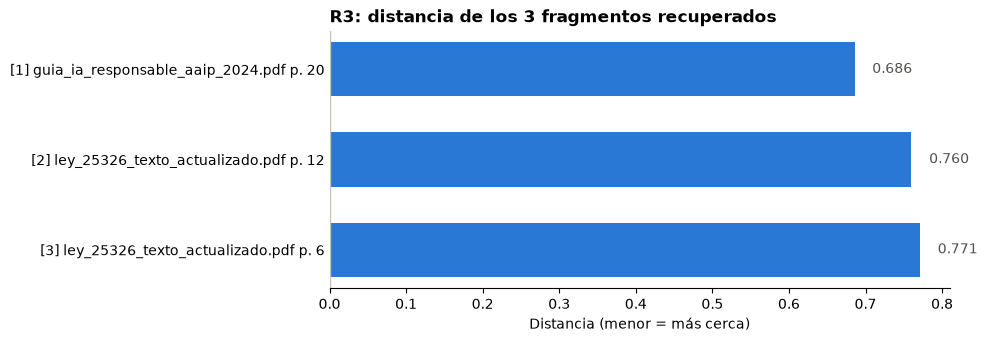


S1 — ¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?
Fuente esperada: No figura: debería abstenerse

[1] guia_ia_responsable_aaip_2024.pdf, p. 30 — distancia 0.908
información sobre estos sistemas y cómo se desarrollaron.
Oportunamente, la AAIP de Argentina y la Unidad Reguladora y de Control de Datos Personales de 
Uruguay, publicaron una Guía “Evaluación de Impacto en la Protección de Datos”. Este instrumen-
to no fue desarrollado específicamente para la eva

[2] guia_ia_responsable_aaip_2024.pdf, p. 46 — distancia 0.974
monitoreo continuo y alertas automáticas. 
También se deben aplicar los protocolos para los incidentes de seguridad, donde la respues-
ta inmediata, la transparencia hacia los ciudadanos y una comunicación fluida al interior y 
exterior de la organización, ya que son cruciales para hacer frente al m

[3] guia_ia_responsable_aaip_2024.pdf, p. 29 — distancia 1.001
Evaluación de Impacto
La Evaluación de Impacto en la Protección de Datos en la etapa de diseñ

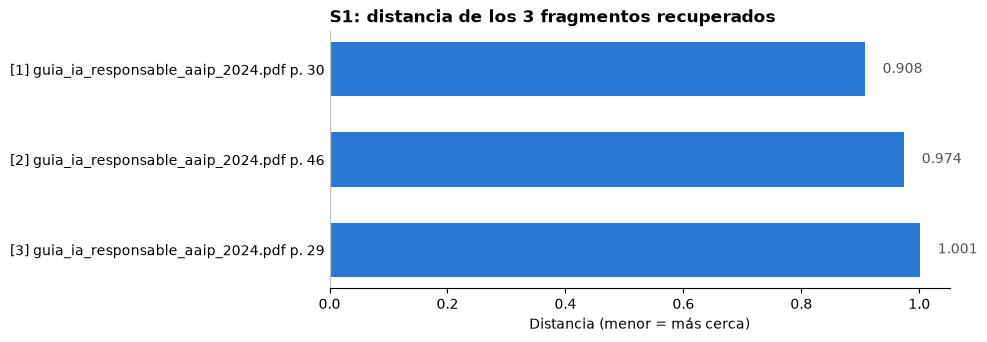


S2 — ¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?
Fuente esperada: No figura: debería abstenerse (la Ley dice que la consulta del registro es gratuita, art. 13, p. 7)

[1] lineamientos_plan_datos_cft_aaip_2023.pdf, p. 18 — distancia 0.649
18
3. Inscripción: informa que las bases de datos personales a su cargo se en-
cuentran inscriptas ante el Registro Nacional de Base de Datos (RNBD). 
El Registro es obligatorio por la ley 25.326, y se implementó desde el 2006. 
Dispone que todo archivo, registro, base o banco de datos personales pú

[2] guia_ia_responsable_aaip_2024.pdf, p. 33 — distancia 0.909
tro Nacional de Bases de Datos Personales18. 
Medidas de seguridad
La seguridad en el tratamiento de datos personales que se utilizan para alimentar un sistema de 
IA, implica la implementación de medidas técnicas y organizativas adecuadas para proteger los 
datos personales contra el acceso no auto

[3] guia_ia_responsable_aaip_2024.pdf, p. 33 — dista

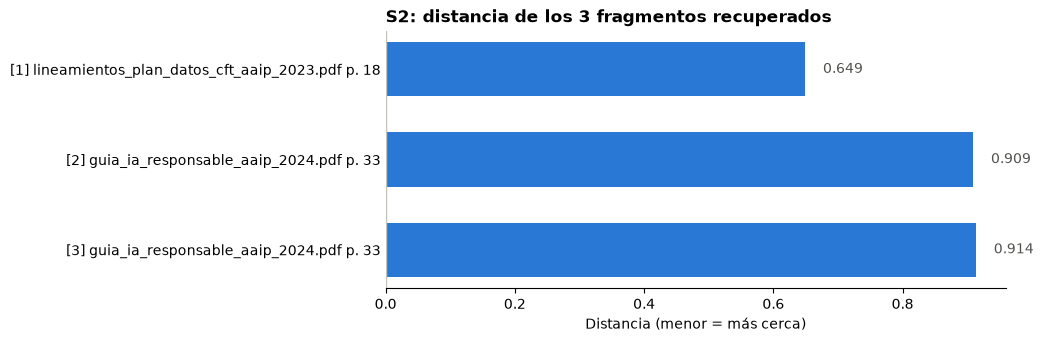


L1 — ¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?
Fuente esperada: Guía, p. 30 (Figura 3): el dato está en una imagen que no se extrae; debería abstenerse

[1] guia_ia_responsable_aaip_2024.pdf, p. 29 — distancia 0.744
de Evaluación de Impacto en la Protección de Datos, elaborada por las agencias de Argenti-
na y Uruguay, se propone una escala para la medición de probabilidad de impacto, con 
cuatro niveles: probabilidad baja, media, alta y crítica17.
La relación entre los riesgos y la probabilidad de impacto perm

[2] guia_ia_responsable_aaip_2024.pdf, p. 29 — distancia 0.838
riesgo. Un proyecto que en el diseño de como resultado una matriz de alto riesgo probable-
mente deba ser desestimado y rediseñado. En la figura 3 se brinda un ejemplo de una 
matriz de riesgo.  
17 Agencia de Acceso a la Información Pública Argentina y Unidad Reguladora y de Control de Datos Person

[3] guia_ia_responsable_aaip_2024.pdf, p. 31 — distancia 0.866
educativos; ca

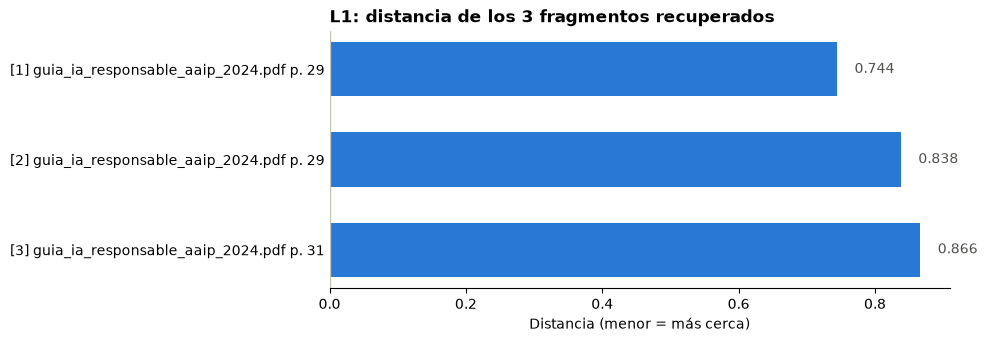

In [77]:
filas_resumen = []

for caso, pregunta, fuente_esperada in casos:
    hallazgos = indice_rag.similarity_search_with_score(query=pregunta, k=K)
    evidencia = evidencias.get(caso)

    print(f"\n{'=' * 70}\n{caso} — {pregunta}")
    print("Fuente esperada:", fuente_esperada)

    etiquetas = []
    distancias = []
    fuentes = []
    hay_evidencia = False

    for numero, (documento, distancia) in enumerate(hallazgos, start=1):
        archivo = Path(documento.metadata["source"]).name
        pagina = documento.metadata["page"] + 1
        print(f"\n[{numero}] {archivo}, p. {pagina} — distancia {distancia:.3f}")
        print(documento.page_content[:300])

        etiquetas.append(f"[{numero}] {archivo} p. {pagina}")
        distancias.append(distancia)
        fuentes.append(f"{archivo} p. {pagina}")

        if evidencia is not None and normalizar(evidencia) in normalizar(documento.page_content):
            hay_evidencia = True

    if evidencia is None:
        evidencia_en_top_k = "no aplica"
    else:
        evidencia_en_top_k = hay_evidencia
    print(f"\nEvidencia en el top-{K}:", evidencia_en_top_k)

    dibujar_barras(
        etiquetas,
        distancias,
        f"{caso}: distancia de los {K} fragmentos recuperados",
        "Distancia (menor = más cerca)",
        formato="{:.3f}",
    )

    textos_distancias = []
    for distancia in distancias:
        textos_distancias.append(f"{distancia:.3f}")

    filas_resumen.append({
        "caso": caso,
        "fuente_esperada": fuente_esperada,
        "fuentes_recuperadas": " | ".join(fuentes),
        "distancias": " | ".join(textos_distancias),
        "evidencia_en_top_k": evidencia_en_top_k,
    })

In [90]:
def mostrar_tabla(df):
    """Muestra el DataFrame completo: texto a la izquierda y con salto de línea dentro de la celda."""
    return (df.style
            .set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
            .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
            .hide(axis="index"))


tabla_recuperacion = pd.DataFrame(filas_resumen)

# La pregunta se toma de la lista casos (justo después de «caso»).
preguntas = {caso: pregunta for caso, pregunta, _ in casos}
tabla_recuperacion.insert(1, "pregunta", tabla_recuperacion["caso"].map(preguntas))

mostrar_tabla(tabla_recuperacion)

caso,pregunta,fuente_esperada,fuentes_recuperadas,distancias,evidencia_en_top_k
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,"Guía, p. 29",guia_ia_responsable_aaip_2024.pdf p. 36 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 30,0.523 | 0.539 | 0.664,False
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,"Lineamientos, p. 27",lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27,0.527 | 0.650 | 0.685,True
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,"Ley 25.326, art. 5, p. 4",guia_ia_responsable_aaip_2024.pdf p. 20 | ley_25326_texto_actualizado.pdf p. 12 | ley_25326_texto_actualizado.pdf p. 6,0.686 | 0.760 | 0.771,False
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,No figura: debería abstenerse,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 46 | guia_ia_responsable_aaip_2024.pdf p. 29,0.908 | 0.974 | 1.001,no aplica
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,"No figura: debería abstenerse (la Ley dice que la consulta del registro es gratuita, art. 13, p. 7)",lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 33,0.649 | 0.909 | 0.914,no aplica
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,"Guía, p. 30 (Figura 3): el dato está en una imagen que no se extrae; debería abstenerse",guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31,0.744 | 0.838 | 0.866,no aplica


In [79]:
# Diagnóstico de los casos cuya evidencia no entró al top-K.
# 1) ¿Algún fragmento del índice contiene la evidencia completa? Si ninguno la
#    contiene, el corte la partió entre dos fragmentos (diagnóstico: corte).
# 2) Si existe, ¿en qué puesto del ranking quedó? Se busca con un K amplio para
#    ver si el buscador la dejó afuera del top-K (diagnóstico: recuperación).
K_AMPLIO = 30

preguntas = {}
for caso, pregunta, fuente_esperada in casos:
    preguntas[caso] = pregunta

for fila in filas_resumen:
    if fila["evidencia_en_top_k"] is not False:
        continue

    caso = fila["caso"]
    evidencia = evidencias[caso]
    print(f"\n{'=' * 70}\n{caso} — evidencia «{evidencia}» no entró al top-{K}")

    # 1) Buscar la evidencia en todos los fragmentos indexados.
    fragmentos_con_evidencia = []
    for numero, fragmento in enumerate(fragmentos_breves):
        if normalizar(evidencia) in normalizar(fragmento.page_content):
            fragmentos_con_evidencia.append(numero)

    if not fragmentos_con_evidencia:
        print("Ningún fragmento contiene la evidencia completa: el corte la partió.")
        print("Diagnóstico: corte.")
        continue

    for numero in fragmentos_con_evidencia:
        fragmento = fragmentos_breves[numero]
        archivo = Path(fragmento.metadata["source"]).name
        pagina = fragmento.metadata["page"] + 1
        print(f"La evidencia está en el fragmento {numero} ({archivo}, p. {pagina}):")
        print(fragmento.page_content[:300])

    # 2) Ver en qué puesto del ranking quedó ese fragmento.
    hallazgos_amplios = indice_rag.similarity_search_with_score(
        query=preguntas[caso], k=K_AMPLIO
    )
    puesto = None
    for posicion, (documento, distancia) in enumerate(hallazgos_amplios, start=1):
        if normalizar(evidencia) in normalizar(documento.page_content):
            puesto = posicion
            print(f"\nQuedó en el puesto {puesto} del ranking (distancia {distancia:.3f}).")
            break

    if puesto is None:
        print(f"\nNo aparece ni entre los primeros {K_AMPLIO}.")
    print("Diagnóstico: recuperación (el fragmento existe, pero no entró al top-K).")


R1 — evidencia «son las que tratan grandes volúmenes de datos» no entró al top-3
La evidencia está en el fragmento 123 (guia_ia_responsable_aaip_2024.pdf, p. 29):
Por lo general aquellas organizaciones que deberían realizar una evaluación de impacto 
son las que tratan grandes volúmenes de datos, que realizan operaciones con datos sensi-
bles, o que realizan una indagación sistemática y exhaustiva de aspectos personales de las 
personas que se base en un trat

Quedó en el puesto 12 del ranking (distancia 0.759).
Diagnóstico: recuperación (el fragmento existe, pero no entró al top-K).

R3 — evidencia «no será necesario el consentimiento» no entró al top-3
La evidencia está en el fragmento 392 (ley_25326_texto_actualizado.pdf, p. 4):
medio que permita se le equipare, de acuerdo a las circunstancias.
El referido consentimiento prestado con otras declaraciones, deberá figurar en forma
expresa y destacada, previa notificación al requerido de datos, de la información descrita
en el artículo

**Observación.** Con el índice base (500/80, K=3):

1. ¿Faltan fragmentos que deberían haber entrado? Sí, en dos de las tres respondibles. R2 recupera la evidencia desde la página esperada en los tres fragmentos. En R1 llega la página correcta (Guía p. 29), pero el fragmento que entra es el título y la definición; el diagnóstico muestra que el fragmento con los criterios («son las que tratan grandes volúmenes de datos») existe entero y quedó en el puesto 12. En R3 la Ley p. 4 no entra: el fragmento con las excepciones del art. 5 quedó en el puesto 8, y además el corte de 500 separó la regla (inciso 1) de las excepciones (inciso 2). En los dos casos el diagnóstico es de recuperación: la evidencia está en el índice, pero el buscador no la ubica entre los tres más cercanos.

2. ¿Entra información irrelevante al contexto? Sí. En R3 entran la Guía p. 20 (la regla sin excepciones) y la Ley p. 12 y p. 6, que mencionan el consentimiento en otros contextos. En los casos sin respuesta Chroma igual devuelve tres vecinos: S1 tiene las distancias más altas (0,91–1,00), pero S2 trae un fragmento sobre la inscripción en el Registro a 0,649, tan cerca como una respondible, así que la distancia no alcanza para detectar que no hay respuesta. L1 recupera el texto que rodea a la matriz, sin sus valores. La abstención va a depender del prompt.

Las primeras frases de evidencia de R1 y R3 aparecían también en otras páginas (Guía p. 35 y p. 45, y Guía p. 20) y daban falsos positivos; se reemplazaron por frases que solo existen en la fuente esperada. Lo que falta en R1 y R3 refuerza la hipótesis de la sección 5 y se pondrá a prueba en la corrida 2.

## 8. Generar sin ocultar la evidencia

La cadena tiene tres pasos explícitos: **plantilla → modelo → texto**. El recuperador queda afuera de la cadena para poder inspeccionarlo: primero se recuperan los fragmentos (como en la sección 7) y después se le pasan al modelo como contexto.

**Qué se considera evidencia:** solo el contexto, es decir, los K=3 fragmentos recuperados, cada uno con su archivo y página. Lo que el modelo «sepa» por su cuenta no cuenta.

**Qué debe pasar si la evidencia falta:** el modelo tiene que responder exactamente la frase fija «No encuentro esa información en los documentos.».

La instrucción pide la abstención, pero no la garantiza: el modelo puede fallar aunque el prompt sea claro. Por eso se prueba con las preguntas sin respuesta (S1 y S2) y con el caso de limitación (L1), y se muestran los fragmentos que recibió el modelo para poder volver a la fuente.

In [80]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama

# Frase fija de abstención: la misma que pide el prompt.
FRASE_ABSTENCION = "No encuentro esa información en los documentos."

plantilla = ChatPromptTemplate.from_messages([
    (
        "system",
        "Respondé en español con una oración completa y sólo con la evidencia "
        "del contexto. Citá [1], [2] o [3] junto a cada afirmación. Si el dato "
        "no está en el contexto, respondé exactamente: No encuentro esa "
        "información en los documentos.",
    ),
    ("human", "Contexto:\n{contexto}\n\nPregunta: {pregunta}"),
])

modelo = ChatOllama(model=MODELO_GENERADOR, temperature=0)
cadena_rag = plantilla | modelo | StrOutputParser()

In [ ]:
filas_generacion = []

for caso, pregunta, fuente_esperada in casos:
    # 1) Recuperar (fuera de la cadena, para poder inspeccionar los fragmentos).
    hallazgos = indice_rag.similarity_search_with_score(query=pregunta, k=K)

    # 2) Armar el contexto con archivo y página de cada fragmento.
    contexto = ""
    referencias = []
    fuentes = []
    for numero, (documento, distancia) in enumerate(hallazgos, start=1):
        archivo = Path(documento.metadata["source"]).name
        pagina = documento.metadata["page"] + 1
        referencias.append(f"[{numero}] {archivo}, página {pagina} — distancia {distancia:.3f}")
        fuentes.append(f"{archivo} p. {pagina}")
        contexto += f"[{numero}] {archivo}, página {pagina}\n{documento.page_content}\n\n"

    # 3) Generar con la cadena: plantilla → modelo → texto.
    respuesta = cadena_rag.invoke({"contexto": contexto, "pregunta": pregunta})

    # 4) Chequeo automático de abstención (texto normalizado).
    # Abstención = la respuesta es exactamente la frase fija (como pide el prompt).
    # Con «contiene» R1 daba True aunque había respondido con tres viñetas y
    # agregado la frase al final.
    se_abstuvo = normalizar(respuesta) == normalizar(FRASE_ABSTENCION)

    print(f"\n{'=' * 70}\n{caso} — {pregunta}")
    print("\nRespuesta:\n", respuesta)
    print("\nFuentes que recibió el modelo:")
    for referencia in referencias:
        print("-", referencia)
    print("\nse_abstuvo:", se_abstuvo)

    filas_generacion.append({
        "caso": caso,
        "respuesta": respuesta,
        "fuentes_recuperadas": " | ".join(fuentes),
        "se_abstuvo": se_abstuvo,
    })


R1 — ¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?

Respuesta:
 En qué casos tu organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA:

- Cuando el sistema de IA maneje datos personales, ya que es fundamental garantizar que la fuente de datos que alimentan los sistemas de IA sea licit y que se apliquen técnicas de minimización de datos para garantizar la privacidad por diseño y por defecto [1].
- Para identificar y mitigar riesgos asociados al tratamiento de datos personales en un sistema de IA desde el principio, como la reidentificación de personas, sesgos algorítmicos y uso indebido de datos [2].
- Cuando se requiera información sobre cómo se desarrollaron los sistemas de IA y se desee cumplir con las regulaciones de protección de datos, como la Guía "Evaluación de Impacto en la Protección de Datos" publicada por la AAIP de Argentina y la

In [91]:
tabla_generacion = pd.DataFrame(filas_generacion)
tabla_generacion.insert(1, "pregunta", tabla_generacion["caso"].map(preguntas))

mostrar_tabla(tabla_generacion)

caso,pregunta,respuesta,fuentes_recuperadas,se_abstuvo
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,"En qué casos tu organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA: - Cuando el sistema de IA maneje datos personales, ya que es fundamental garantizar que la fuente de datos que alimentan los sistemas de IA sea licit y que se apliquen técnicas de minimización de datos para garantizar la privacidad por diseño y por defecto [1]. - Para identificar y mitigar riesgos asociados al tratamiento de datos personales en un sistema de IA desde el principio, como la reidentificación de personas, sesgos algorítmicos y uso indebido de datos [2]. - Cuando se requiera información sobre cómo se desarrollaron los sistemas de IA y se desee cumplir con las regulaciones de protección de datos, como la Guía ""Evaluación de Impacto en la Protección de Datos"" publicada por la AAIP de Argentina y la Unidad Reguladora y de Control de Datos Personales de Uruguay [3]. No encuentro esa información en los documentos.",guia_ia_responsable_aaip_2024.pdf p. 36 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 30,False
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,"Al contratar un proveedor de nube para alojar datos personales, es fundamental investigar y elegir uno que ofrezca altos estándares de seguridad y cumpla con las regulaciones de privacidad, especialmente considerando que en el país no hay muchos prestadores del servicio y la mayoría de los proveedores son extranjeros, lo que puede involucrar transferencias internacionales de datos personales. Además, es necesario un acuerdo con el encargado de tratamiento que detalle el objeto y el alcance del acuerdo, el plazo, la ubicación, la naturaleza y la finalidad de los datos personales a ser tratados, y destacar que para la administración, el alojamiento de datos en la nube también es una parte del tratamiento, por lo que debe figurar como tal en el acuerdo. [1], [2], [3]",lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27,False
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,No encuentro esa información en los documentos.,guia_ia_responsable_aaip_2024.pdf p. 20 | ley_25326_texto_actualizado.pdf p. 12 | ley_25326_texto_actualizado.pdf p. 6,True
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,No encuentro esa información en los documentos.,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 46 | guia_ia_responsable_aaip_2024.pdf p. 29,True
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,No encuentro esa información en los documentos.,lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 33,True
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,No encuentro esa información en los documentos.,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31,True


**Observación.** 

1. ¿La respuesta usa solo la evidencia y cita bien? R2 responde con la evidencia de la página esperada, aunque agrupa las citas al final en lugar de ponerlas junto a cada afirmación. R1 no recibió el fragmento con los criterios (quedó en el puesto 12) y respondió igual: tres viñetas citadas que hablan de privacidad por diseño y de los riesgos que detecta la evaluación, pero no de en qué casos corresponde hacerla; al final agregó la frase de abstención, una respuesta contradictoria. Tampoco respetó la instrucción de «una oración completa».

2. ¿S1, S2 y L1 se abstuvieron? Sí, los tres. S2 no cayó en la trampa del fragmento sobre la inscripción en el Registro y L1 no inventó un valor de la matriz. R3 también se abstuvo: recibió la regla (Guía p. 20) pero no las excepciones (Ley p. 4), y la pregunta pide ambas.

3. Si una respuesta falla, ¿falló la recuperación o la generación? En R3 falló la recuperación: el modelo se abstuvo porque la evidencia no llegó. En R1 fallaron las dos: la recuperación no trajo los criterios y la generación respondió sin ellos en lugar de abstenerse. El chequeo de abstención se cambió a igualdad exacta con la frase fija: con «contiene», R1 figuraba como abstención aunque había respondido.

## 9. Auditoría: una variable por vez

El método es el de los cuadernos 06 y 07 de clase:

1. **Primero se audita la recuperación**: ¿la evidencia esperada aparece en los `k` fragmentos? Se compara el texto normalizado, porque el PDF corta líneas.
2. **Después se audita la generación**: ¿usó la evidencia, citó bien, se abstuvo cuando correspondía?
3. **Diagnóstico por caso**: ok / extracción / corte / recuperación / generación.
4. **Se cambia una sola variable por corrida** (`chunk_size`, `chunk_overlap`, `k` o el prompt) y se registra el antes y el después.

Cada corrida **agrega** filas a `pruebas/auditoria.csv` (una por caso). Como al reejecutar el cuaderno las salidas se pisan, el CSV es el historial.

La **corrida 1** es la base de clase: fragmentos de 500 con solapamiento 80 y `K = 3`, la misma configuración de las secciones 7 y 8.

La función propone un diagnóstico con una regla simple; lo reviso yo leyendo la respuesta y los fragmentos.

| Tipo | Evidencia en top-k | ¿Se abstuvo? | Diagnóstico sugerido |
|---|---|---|---|
| respondible | sí | no | ok |
| respondible | no | (cualquiera) | recuperación |
| respondible | sí | sí | generación |
| sin respuesta / limitación | no aplica | sí | ok |
| sin respuesta / limitación | no aplica | no | generación |


In [83]:
# Función de auditoría: repite lo de las secciones 7 y 8 para los 6 casos
# y devuelve una fila por caso con las 20 columnas del registro.
from datetime import datetime

COLUMNAS_AUDITORIA = [
    "corrida", "fecha", "cambio_respecto_anterior", "chunk_size", "chunk_overlap", "k",
    "modelo_embeddings", "modelo_generador", "caso", "tipo", "pregunta",
    "evidencia_esperada", "fuente_esperada", "fuentes_recuperadas", "distancias",
    "evidencia_en_top_k", "respuesta", "se_abstuvo", "diagnostico", "observacion",
]


def correr_auditoria(numero_corrida, cambio, indice, tamano, solapamiento, k=K):
    filas = []
    fecha = datetime.now().strftime("%Y-%m-%d %H:%M")

    for caso, pregunta, fuente_esperada in casos:
        evidencia = evidencias.get(caso)

        # 1) Recuperar con k fragmentos.
        hallazgos = indice.similarity_search_with_score(query=pregunta, k=k)

        # 2) Armar el contexto y revisar si está la evidencia.
        contexto = ""
        fuentes = []
        distancias = []
        hay_evidencia = False
        for numero, (documento, distancia) in enumerate(hallazgos, start=1):
            archivo = Path(documento.metadata["source"]).name
            pagina = documento.metadata["page"] + 1
            fuentes.append(f"{archivo} p. {pagina}")
            distancias.append(f"{distancia:.3f}")
            contexto += f"[{numero}] {archivo}, página {pagina}\n{documento.page_content}\n\n"
            if evidencia is not None and normalizar(evidencia) in normalizar(documento.page_content):
                hay_evidencia = True

        if evidencia is None:
            evidencia_en_top_k = "no aplica"
        else:
            evidencia_en_top_k = hay_evidencia

        # 3) Generar con la misma cadena de la sección 8.
        respuesta = cadena_rag.invoke({"contexto": contexto, "pregunta": pregunta})

        # 4) Abstención: la respuesta es exactamente la frase fija (texto normalizado).
        se_abstuvo = normalizar(respuesta) == normalizar(FRASE_ABSTENCION)

        # 5) Tipo de caso y diagnóstico sugerido (lo reviso yo después).
        if caso.startswith("R"):
            tipo = "respondible"
            if evidencia_en_top_k is False:
                diagnostico = "recuperación"
            elif se_abstuvo:
                diagnostico = "generación"
            else:
                diagnostico = "ok"
        else:
            tipo = "sin respuesta" if caso.startswith("S") else "limitación"
            diagnostico = "ok" if se_abstuvo else "generación"

        filas.append({
            "corrida": numero_corrida,
            "fecha": fecha,
            "cambio_respecto_anterior": cambio,
            "chunk_size": tamano,
            "chunk_overlap": solapamiento,
            "k": k,
            "modelo_embeddings": MODELO_EMBEDDINGS,
            "modelo_generador": MODELO_GENERADOR,
            "caso": caso,
            "tipo": tipo,
            "pregunta": pregunta,
            "evidencia_esperada": evidencia if evidencia is not None else "",
            "fuente_esperada": fuente_esperada,
            "fuentes_recuperadas": " | ".join(fuentes),
            "distancias": " | ".join(distancias),
            "evidencia_en_top_k": evidencia_en_top_k,
            "respuesta": respuesta,
            "se_abstuvo": se_abstuvo,
            "diagnostico": diagnostico,
            "observacion": "",
        })

    return pd.DataFrame(filas, columns=COLUMNAS_AUDITORIA)


In [93]:
# Corrida 1: base de clase (500 / 80, K = 3), con el índice de la sección 6.
df_corrida_1 = correr_auditoria(1, "base de clase", indice_rag, 500, 80)

In [94]:
# Vista de la corrida 1 (el texto de la respuesta va completo; no vuelve a generar nada).
vista = df_corrida_1[["caso", "pregunta", "tipo", "fuentes_recuperadas", "evidencia_en_top_k", "se_abstuvo", "diagnostico", "respuesta"]]
mostrar_tabla(vista)

caso,pregunta,tipo,fuentes_recuperadas,evidencia_en_top_k,se_abstuvo,diagnostico,respuesta
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,respondible,guia_ia_responsable_aaip_2024.pdf p. 36 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 30,False,False,recuperación,"En qué casos tu organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA: - Cuando el sistema de IA procesa datos personales, es necesario considerar la privacidad por diseño y por defecto para que sean objeto de tratamiento solo aquellos datos personales necesarios, garantizar que la fuente de datos que alimentan los sistemas de IA sea lícita y asegurar el tratamiento de datos personales aplicando técnicas de minimización [1]. - Deberías realizar una evaluación de impacto en la protección de datos en la etapa de diseño, ya que es una herramienta fundamental para identificar y mitigar riesgos asociados al tratamiento de datos personales en un sistema de Inteligencia Artificial desde el principio, como la reidentificación de personas, sesgos algorítmicos, uso indebido de datos, entre otros [2]. - Si tu organización publica información sobre cómo se desarrollaron los sistemas de IA y desea cumplir con las regulaciones de protección de datos, es recomendable realizar una evaluación de impacto en la protección de datos, ya que aunque la Guía ""Evaluación de Impacto en la Protección de Datos"" no fue desarrollada específicamente para la evaluación de impacto de sistemas que utilicen la Inteligencia Artificial, es aplicable en la medida que estos sistemas utilicen datos personales [3]."
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,respondible,lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27,True,False,ok,"Al contratar un proveedor de nube para alojar datos personales, debes tener en cuenta investigar y elegir uno que ofrezca altos estándares de seguridad y cumpla con las regulaciones de privacidad, considerar la ubicación y naturaleza de los datos, asegurar que el acuerdo detalle el objeto y alcance del acuerdo, la finalidad de los datos personales tratados, y reconocer que alojar datos en la nube implica tratamiento de esos datos. [1], [2], [3]"
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,respondible,guia_ia_responsable_aaip_2024.pdf p. 20 | ley_25326_texto_actualizado.pdf p. 12 | ley_25326_texto_actualizado.pdf p. 6,False,True,recuperación,No encuentro esa información en los documentos.
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,sin respuesta,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 46 | guia_ia_responsable_aaip_2024.pdf p. 29,no aplica,True,ok,No encuentro esa información en los documentos.
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,sin respuesta,lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 33,no aplica,True,ok,No encuentro esa información en los documentos.
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,limitación,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31,no aplica,False,generación,"Un valor de riesgo que corresponde a una probabilidad alta con un impacto crítico es un riesgo alto significativo para la salud, la seguridad o los derechos fundamentales, donde los sistemas deben cumplir estrictos requisitos antes de ser desplegados. [1][2]"


In [95]:
# Completo a mano: observaciones por caso y, si no coincido con la regla, el diagnóstico corregido.
OBSERVACIONES_CORRIDA_1 = {
    "R1": "Llega la Guía p. 29 pero no el fragmento con los criterios (puesto 12). El modelo responde igual con 3 viñetas que no dicen en qué casos corresponde la evaluación: no se abstiene.",
    "R2": "Los 3 fragmentos son de Lineamientos p. 27 y contienen la evidencia. Responde bien; agrupa las citas al final en lugar de ponerlas junto a cada afirmación.",
    "R3": "No llega la Ley p. 4 (el fragmento con las excepciones quedó en el puesto 8). Llega la regla sin excepciones (Guía p. 20) y el modelo se abstiene.",
    "S1": "Distancias más altas de los 6 casos (0,91 a 1,00). Se abstiene correctamente.",
    "S2": "Llega un fragmento sobre la inscripción en el Registro a 0,649, tan cerca como una respondible. No cae en la trampa: se abstiene.",
    "L1": "Llega el texto alrededor de la matriz, sin sus valores. En la sección 8 se abstuvo; en esta corrida respondió con la descripción de riesgo alto de la Guía p. 31 (otro tema) y la citó como [1][2]. La abstención no es estable entre ejecuciones.",
}

# Ejemplo: {"R1": "generación"}. Vacío = se queda el diagnóstico sugerido.
DIAGNOSTICOS_CORREGIDOS_1 = {}

df_corrida_1["observacion"] = df_corrida_1["caso"].map(OBSERVACIONES_CORRIDA_1).fillna("")
for caso, diagnostico_corregido in DIAGNOSTICOS_CORREGIDOS_1.items():
    df_corrida_1.loc[df_corrida_1["caso"] == caso, "diagnostico"] = diagnostico_corregido

mostrar_tabla(df_corrida_1[["caso", "pregunta", "diagnostico", "observacion"]])

caso,pregunta,diagnostico,observacion
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,recuperación,Llega la Guía p. 29 pero no el fragmento con los criterios (puesto 12). El modelo responde igual con 3 viñetas que no dicen en qué casos corresponde la evaluación: no se abstiene.
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,ok,Los 3 fragmentos son de Lineamientos p. 27 y contienen la evidencia. Responde bien; agrupa las citas al final en lugar de ponerlas junto a cada afirmación.
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,recuperación,No llega la Ley p. 4 (el fragmento con las excepciones quedó en el puesto 8). Llega la regla sin excepciones (Guía p. 20) y el modelo se abstiene.
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,ok,"Distancias más altas de los 6 casos (0,91 a 1,00). Se abstiene correctamente."
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,ok,"Llega un fragmento sobre la inscripción en el Registro a 0,649, tan cerca como una respondible. No cae en la trampa: se abstiene."
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,generación,"Llega el texto alrededor de la matriz, sin sus valores. En la sección 8 se abstuvo; en esta corrida respondió con la descripción de riesgo alto de la Guía p. 31 (otro tema) y la citó como [1][2]. La abstención no es estable entre ejecuciones."


In [96]:
# Guardo la corrida 1 en pruebas/auditoria.csv (historial). Si ya hay filas de esa corrida, se reemplazan.
RUTA_AUDITORIA = Path("pruebas/auditoria.csv")
RUTA_AUDITORIA.parent.mkdir(exist_ok=True)

if RUTA_AUDITORIA.exists():
    historial = pd.read_csv(RUTA_AUDITORIA, dtype=str, keep_default_na=False)
    historial = historial[historial["corrida"] != "1"]
    todas = pd.concat([historial, df_corrida_1.astype(str)], ignore_index=True)
else:
    todas = df_corrida_1.astype(str)

todas.to_csv(RUTA_AUDITORIA, index=False, encoding="utf-8")
print("Filas en", RUTA_AUDITORIA, ":", len(pd.read_csv(RUTA_AUDITORIA, encoding="utf-8")))


Filas en pruebas\auditoria.csv : 6


### Diagnóstico — corrida 1

Recuperación. R2 funciona. En R1 y R3 la evidencia existe en el índice pero no entra al top-3 (puestos 12 y 8): el diagnóstico es de recuperación, y en R3 además el corte de 500 separó la regla de las excepciones del art. 5. Los fragmentos recuperados son idénticos a los de la sección 7: la recuperación es estable.

Generación. S1 y S2 se abstienen; S2 resiste un fragmento muy cercano sobre la inscripción. R1 responde sin la evidencia en lugar de abstenerse. L1, que en la sección 8 se había abstenido, en esta corrida respondió con información de otro tema y con una cita equivocada, con los mismos fragmentos y temperature=0. La abstención se pide en el prompt, pero no la asegura: con los mismos fragmentos, en la sección 8 se abstuvo y en la auditoría respondió, y cada una repite su resultado al volver a correrla.

Qué se cambia en la corrida 2. Solo el corte, a 1.100/180, porque los dos fallos de las respondibles son de recuperación y la sección 5 mostró que el corte amplio trae la regla y las excepciones de R3 juntas. Al comparar, se mira primero la recuperación, que es estable; las diferencias en las respuestas se leen con cautela.



### Corrida 2: cambia solo el corte

**Qué se cambia:** el corte de los fragmentos, de 500/80 a **1.100/180**. **Qué queda igual:** `K = 3`, el modelo de embeddings (`bge-m3`), el generador (`granite4:latest`, `temperature=0`) y el prompt.

**Por qué:** en la corrida 1 los fallos de R1 y R3 fueron de recuperación (la evidencia estaba en el índice, en los puestos 12 y 8, pero no entró al top-3). En la sección 5 el corte amplio trajo la regla y las excepciones de R3 juntas. Si la hipótesis es correcta, R1 y R3 deberían mejorar.

Como cambia el corte, se crea otra colección, `integrador_1100_180_bge_m3`, en la misma carpeta: no se mezclan vectores con los de la corrida 1.


In [97]:
NOMBRE_COLECCION_AMPLIA = "integrador_1100_180_bge_m3"

indice_amplio_rag = Chroma(
    collection_name=NOMBRE_COLECCION_AMPLIA,
    embedding_function=embeddings,
    persist_directory=CARPETA_INDICE,
)

# Si la colección ya tiene datos, se borra y se recrea para no duplicar fragmentos.
if indice_amplio_rag.get(limit=1)["ids"]:
    indice_amplio_rag.delete_collection()
    indice_amplio_rag = Chroma(
        collection_name=NOMBRE_COLECCION_AMPLIA,
        embedding_function=embeddings,
        persist_directory=CARPETA_INDICE,
    )

identificadores_amplios = []
for numero in range(len(fragmentos_amplios)):
    identificadores_amplios.append(f"fragmento_{numero}")

# Se indexa por lotes, igual que en la sección 6.
for inicio in range(0, len(fragmentos_amplios), TAMANO_LOTE):
    fin = inicio + TAMANO_LOTE
    indice_amplio_rag.add_documents(
        documents=fragmentos_amplios[inicio:fin],
        ids=identificadores_amplios[inicio:fin],
    )
    print("Indexados hasta el fragmento", min(fin, len(fragmentos_amplios)))

cantidad_indexada_amplia = len(indice_amplio_rag.get()["ids"])
print("Colección:", NOMBRE_COLECCION_AMPLIA)
print("Fragmentos indexados:", cantidad_indexada_amplia, "| fragmentos amplios:", len(fragmentos_amplios))
assert cantidad_indexada_amplia == len(fragmentos_amplios)


Indexados hasta el fragmento 50
Indexados hasta el fragmento 100
Indexados hasta el fragmento 150
Indexados hasta el fragmento 200
Indexados hasta el fragmento 239
Colección: integrador_1100_180_bge_m3
Fragmentos indexados: 239 | fragmentos amplios: 239


In [98]:
df_corrida_2 = correr_auditoria(2, "corte 1.100/180 (antes 500/80)", indice_amplio_rag, 1100, 180)


In [99]:
# Vista de la corrida 2 (mismas columnas que la de la corrida 1; no vuelve a generar nada).
vista_2 = df_corrida_2[["caso", "pregunta", "tipo", "fuentes_recuperadas", "evidencia_en_top_k", "se_abstuvo", "diagnostico", "respuesta"]]
mostrar_tabla(vista_2)


caso,pregunta,tipo,fuentes_recuperadas,evidencia_en_top_k,se_abstuvo,diagnostico,respuesta
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,respondible,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 34 | guia_ia_responsable_aaip_2024.pdf p. 30,True,True,generación,No encuentro esa información en los documentos.
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,respondible,lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 28,True,False,ok,"Al contratar un proveedor de nube para alojar datos personales, debes tener en cuenta investigar y elegir uno que ofrezca altos estándares de seguridad y cumpla con las regulaciones de privacidad, considerar si el proveedor es público o privado, asegurarte de que el contrato detalle el objeto y el alcance del acuerdo, el plazo, la ubicación, la naturaleza y la finalidad de los datos, incluir una previsión respecto al deber de confidencialidad y las medidas de seguridad, y contemplar los derechos de los titulares en el contrato de servicios. [1], [2], [3]"
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,respondible,guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 28 | ley_25326_texto_actualizado.pdf p. 4,True,True,generación,No encuentro esa información en los documentos.
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,sin respuesta,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 34,no aplica,True,ok,No encuentro esa información en los documentos.
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,sin respuesta,lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 21,no aplica,True,ok,No encuentro esa información en los documentos.
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,limitación,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31 | guia_ia_responsable_aaip_2024.pdf p. 29,no aplica,True,ok,No encuentro esa información en los documentos.


In [100]:
# Diagnóstico de los casos de la corrida 2 cuya evidencia no entró al top-K
# (mismo método que la sección 7, pero con el corte 1.100/180).
# 1) ¿Algún fragmento amplio contiene la evidencia completa? Si ninguno, el corte la partió.
# 2) Si existe, ¿en qué puesto del ranking quedó? Se busca con K_AMPLIO.
hubo_fallos = False

for _, fila in df_corrida_2.iterrows():
    if fila["evidencia_en_top_k"] is not False:
        continue

    hubo_fallos = True
    caso = fila["caso"]
    evidencia = evidencias[caso]
    print(f"\n{'=' * 70}\n{caso} — evidencia «{evidencia}» no entró al top-{K}")

    # 1) Buscar la evidencia en todos los fragmentos amplios.
    fragmentos_con_evidencia = []
    for numero, fragmento in enumerate(fragmentos_amplios):
        if normalizar(evidencia) in normalizar(fragmento.page_content):
            fragmentos_con_evidencia.append(numero)

    if not fragmentos_con_evidencia:
        print("Ningún fragmento contiene la evidencia completa: el corte la partió.")
        print("Diagnóstico: corte.")
        continue

    for numero in fragmentos_con_evidencia:
        fragmento = fragmentos_amplios[numero]
        archivo = Path(fragmento.metadata["source"]).name
        pagina = fragmento.metadata["page"] + 1
        print(f"La evidencia está en el fragmento {numero} ({archivo}, p. {pagina}):")
        print(fragmento.page_content[:300])

    # 2) Ver en qué puesto del ranking quedó ese fragmento.
    hallazgos_amplios = indice_amplio_rag.similarity_search_with_score(
        query=fila["pregunta"], k=K_AMPLIO
    )
    puesto = None
    for posicion, (documento, distancia) in enumerate(hallazgos_amplios, start=1):
        if normalizar(evidencia) in normalizar(documento.page_content):
            puesto = posicion
            print(f"\nQuedó en el puesto {puesto} del ranking (distancia {distancia:.3f}).")
            break

    if puesto is None:
        print(f"\nNo aparece ni entre los primeros {K_AMPLIO}.")
    print("Diagnóstico: recuperación (el fragmento existe, pero no entró al top-K).")

if not hubo_fallos:
    print(f"En la corrida 2 todas las respondibles tienen la evidencia en el top-{K}: no hay nada que diagnosticar.")


En la corrida 2 todas las respondibles tienen la evidencia en el top-3: no hay nada que diagnosticar.


In [105]:
# Completo a mano después de leer la tabla y el diagnóstico de la corrida 2.
OBSERVACIONES_CORRIDA_2 = {
    "R1": "Con el corte amplio la Guía p. 29 entra primera y trae los criterios, pero el modelo se abstiene igual. Mejoró la búsqueda, no la respuesta.",
    "R2": "Los 3 fragmentos son de Lineamientos (p. 27 y 28). Responde bien y más completo que en la corrida 1; sigue agrupando las citas al final.",
    "R3": "Ahora entra la Ley p. 4 con las excepciones del art. 5 (tercera), pero el modelo se abstiene. Igual que R1: la evidencia llega y no la usa.",
    "S1": "Se abstiene correctamente.",
    "S2": "Vuelve a llegar el fragmento sobre la inscripción en el Registro. Se abstiene correctamente.",
    "L1": "Llega el texto alrededor de la matriz, sin sus valores. Esta vez se abstiene; en la corrida 1 había respondido con información de otro tema.",
}

# Ejemplo: {"R1": "generación"}. Vacío = se queda el diagnóstico sugerido.
DIAGNOSTICOS_CORREGIDOS_2 = {}

df_corrida_2["observacion"] = df_corrida_2["caso"].map(OBSERVACIONES_CORRIDA_2).fillna("")
for caso, diagnostico_corregido in DIAGNOSTICOS_CORREGIDOS_2.items():
    df_corrida_2.loc[df_corrida_2["caso"] == caso, "diagnostico"] = diagnostico_corregido

mostrar_tabla(df_corrida_2[["caso", "pregunta", "diagnostico", "observacion"]])


caso,pregunta,diagnostico,observacion
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,generación,"Con el corte amplio la Guía p. 29 entra primera y trae los criterios, pero el modelo se abstiene igual. Mejoró la búsqueda, no la respuesta."
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,ok,Los 3 fragmentos son de Lineamientos (p. 27 y 28). Responde bien y más completo que en la corrida 1; sigue agrupando las citas al final.
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,generación,"Ahora entra la Ley p. 4 con las excepciones del art. 5 (tercera), pero el modelo se abstiene. Igual que R1: la evidencia llega y no la usa."
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,ok,Se abstiene correctamente.
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,ok,Vuelve a llegar el fragmento sobre la inscripción en el Registro. Se abstiene correctamente.
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,ok,"Llega el texto alrededor de la matriz, sin sus valores. Esta vez se abstiene; en la corrida 1 había respondido con información de otro tema."


In [106]:
# Guardo la corrida 2 en pruebas/auditoria.csv. Si ya hay filas de esa corrida, se reemplazan;
# las filas de la corrida 1 no se tocan.
historial = pd.read_csv(RUTA_AUDITORIA, dtype=str, keep_default_na=False)
historial = historial[historial["corrida"] != "2"]
todas = pd.concat([historial, df_corrida_2.astype(str)], ignore_index=True)

todas.to_csv(RUTA_AUDITORIA, index=False, encoding="utf-8")
cantidad_filas = len(pd.read_csv(RUTA_AUDITORIA, encoding="utf-8"))
print("Filas en", RUTA_AUDITORIA, ":", cantidad_filas)
assert cantidad_filas == 12


Filas en pruebas\auditoria.csv : 12


In [107]:
# Comparación de las dos corridas, leyendo el historial guardado en el CSV.
historial = pd.read_csv(RUTA_AUDITORIA, dtype=str, keep_default_na=False)
corrida_1 = historial[historial["corrida"] == "1"]
corrida_2 = historial[historial["corrida"] == "2"]

columnas_a_comparar = ["fuentes_recuperadas", "evidencia_en_top_k", "se_abstuvo", "diagnostico"]

comparacion = corrida_1[["caso", "pregunta"] + columnas_a_comparar].merge(
    corrida_2[["caso"] + columnas_a_comparar],
    on="caso",
    suffixes=("_1", "_2"),
)

orden_columnas = ["caso", "pregunta"]
for columna in columnas_a_comparar:
    orden_columnas += [columna + "_1", columna + "_2"]

mostrar_tabla(comparacion[orden_columnas])


caso,pregunta,fuentes_recuperadas_1,fuentes_recuperadas_2,evidencia_en_top_k_1,evidencia_en_top_k_2,se_abstuvo_1,se_abstuvo_2,diagnostico_1,diagnostico_2
R1,¿En qué casos mi organización debería hacer una evaluación de impacto en protección de datos antes de desarrollar un sistema de IA?,guia_ia_responsable_aaip_2024.pdf p. 36 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 30,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 34 | guia_ia_responsable_aaip_2024.pdf p. 30,False,True,False,True,recuperación,generación
R2,¿Qué debo tener en cuenta al contratar un proveedor de nube para alojar datos personales?,lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27,lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 27 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 28,True,True,False,False,ok,ok
R3,¿Necesito el consentimiento de las personas para usar sus datos personales en mi proyecto? ¿Hay excepciones?,guia_ia_responsable_aaip_2024.pdf p. 20 | ley_25326_texto_actualizado.pdf p. 12 | ley_25326_texto_actualizado.pdf p. 6,guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 28 | ley_25326_texto_actualizado.pdf p. 4,False,True,True,True,recuperación,generación
S1,¿Cuánto tarda la AAIP en aprobar una evaluación de impacto?,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 46 | guia_ia_responsable_aaip_2024.pdf p. 29,guia_ia_responsable_aaip_2024.pdf p. 30 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 34,no aplica,no aplica,True,True,ok,ok
S2,¿Cuánto cuesta inscribir una base de datos en el Registro Nacional de Bases de Datos?,lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | guia_ia_responsable_aaip_2024.pdf p. 33,lineamientos_plan_datos_cft_aaip_2023.pdf p. 18 | guia_ia_responsable_aaip_2024.pdf p. 33 | lineamientos_plan_datos_cft_aaip_2023.pdf p. 21,no aplica,no aplica,True,True,ok,ok
L1,¿Qué valor de riesgo corresponde a una probabilidad alta con un impacto crítico?,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31,guia_ia_responsable_aaip_2024.pdf p. 29 | guia_ia_responsable_aaip_2024.pdf p. 31 | guia_ia_responsable_aaip_2024.pdf p. 29,no aplica,no aplica,False,True,generación,ok


### Diagnóstico — corrida 2 y comparación

Cambiar el corte a 1.100/180 hizo lo que esperaba en la búsqueda: en R1 y R3 la evidencia ahora llega entre los tres primeros fragmentos (la Guía p. 29 primera y la Ley p. 4 tercera). Pero las respuestas no mejoraron: en los dos casos el modelo se abstuvo teniendo la evidencia en el contexto. El problema pasó de la recuperación a la generación.

No sé con certeza por qué se abstiene. Una posibilidad es que, con fragmentos más largos y temas mezclados, al modelo le cueste armar la respuesta en «una oración completa», como pide el prompt, sobre todo en R3, que pregunta por la regla y por las excepciones. Para comprobarlo cambiaría solo el prompt en una tercera corrida, por ejemplo permitiendo una respuesta de varias oraciones.

R2, S1 y S2 se comportaron igual en las dos corridas. L1 se abstuvo esta vez, después de haber inventado una respuesta en la corrida 1: otra muestra de que la abstención no es estable.

Corte elegido. Me quedo con 1.100/180 porque es el que trae al contexto la evidencia de las tres respondibles. Descarto 500/80: con ese corte la búsqueda falla en dos de las tres (R1 y R3 quedan fuera del top-3), y su única ventaja, fragmentos más cortos y enfocados, no compensa que la evidencia no llegue. Que el modelo no use la evidencia con el corte amplio es un problema de generación, que queda documentado como límite.